<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/9a_NODE_for_time_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# II. Neural Ordinary Differential Equations (NODE) (by Chen et al, 2018):

Ricky T. Q. Chen, Yulia Rubanova, Jesse Bettencourt, David Duvenaud, NEural Ordinary differential Equations, 2018 https://arxiv.org/pdf/1806.07366


$$ h(t)=h(0)+\int_0^s f(s,h(s))ds$$
 $$f(s,h(s) )\approx\frac{dh(t)}{dt} \approx NN(h(t),t,\theta_f )$$
Use a neural network to represent the ODEs ($\frac{dh(t)}{dt}$), and pass it through a ODE solver (e.g., Euler's or Runge Kutta), to solve for $h(t)$ which is then compared to real $h(t)$ data to determine loss. Backprop needs to be done in the ODE solver. Regular backprop can be inefficient, more efficient adjoint method is typically used.

Code source: https://github.com/rtqichen/torchdiffeq/blob/master/examples/ode_demo.py





# III. RNN v NODE

While an RNN models sequential data by taking discrete steps, a NDEs on general can be viewed as a continuous-time generalization of a ResNet or RNN.

* **In RNN (Discrete Steps)** we use: $h_{t+1}=h_{t}+f(h_{t},\theta )$
An RNN updates its state layer-by-layer or step-by-step in fixed, discrete intervals.
* **In  ResNet (Residual Network) (a CNN architecture)** these are equivalent to the skip connections.
- **Neural ODE (Continuous Flow)**: $\frac{dh(t)}{dt}=f(h(t),t,\theta )$ Applies ODE solvers to solve for $h(t)$, and thus it can be represented in continuous-time.

**NODEs (by Chen et. al., 2018) v Neural CDEs**
* NODEs model continuous state changes driven by an initial condition, which perfectly mirrors a ResNet. But it has time that makes it similar to RNN.
* However NODEs (Chen et. al., 2018) are not exactly RNN analogue, e.g., in way it handles outside signals.
* Neural CDEs (Controlled Differential Equations) can process incoming sequential data streams at every moment, making them the true continuous analogue to RNNs.
We will look at NeuralCDEs in future lectures

## **Data preparation is similar for RNN and NODE**
Below shows a snapshot of the sliding window for forecasting tasks.

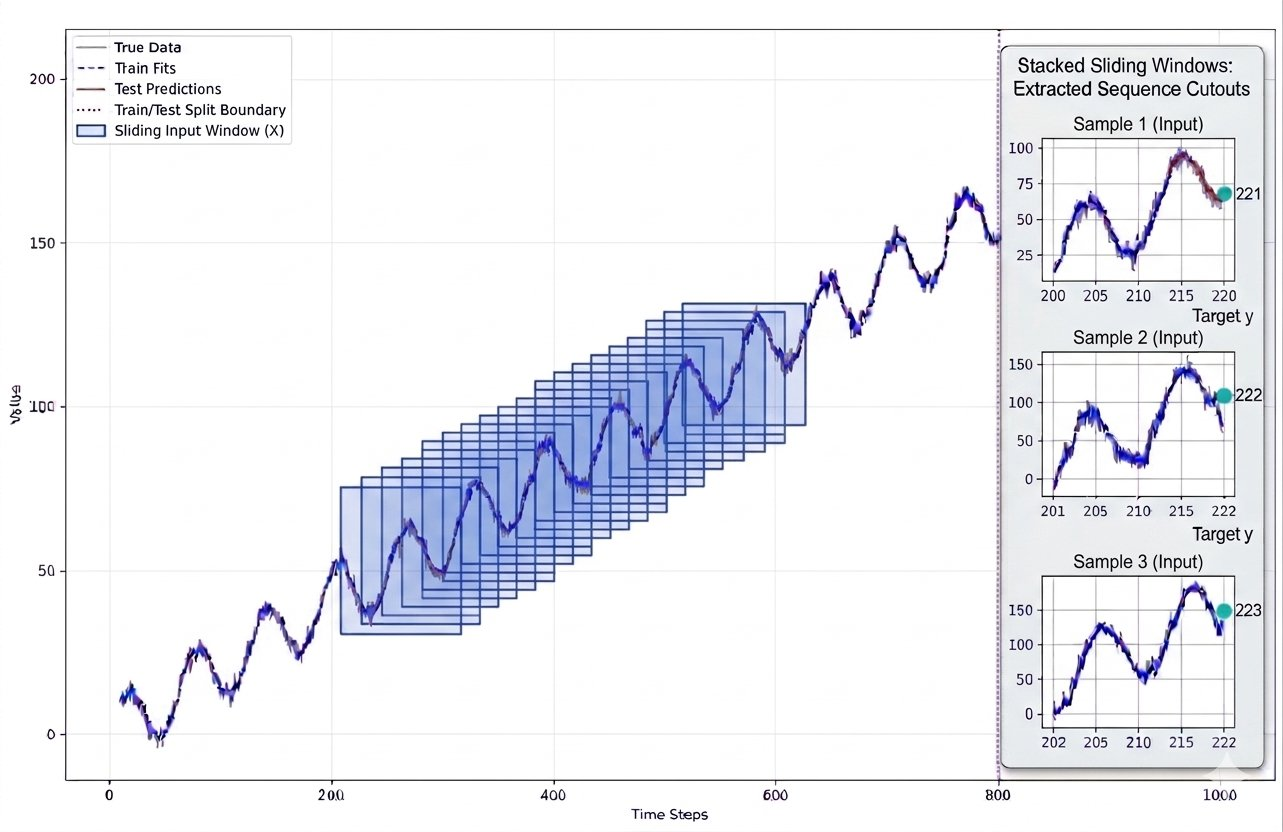

## **Overview of RNN and NODE for regularly sampled signals**

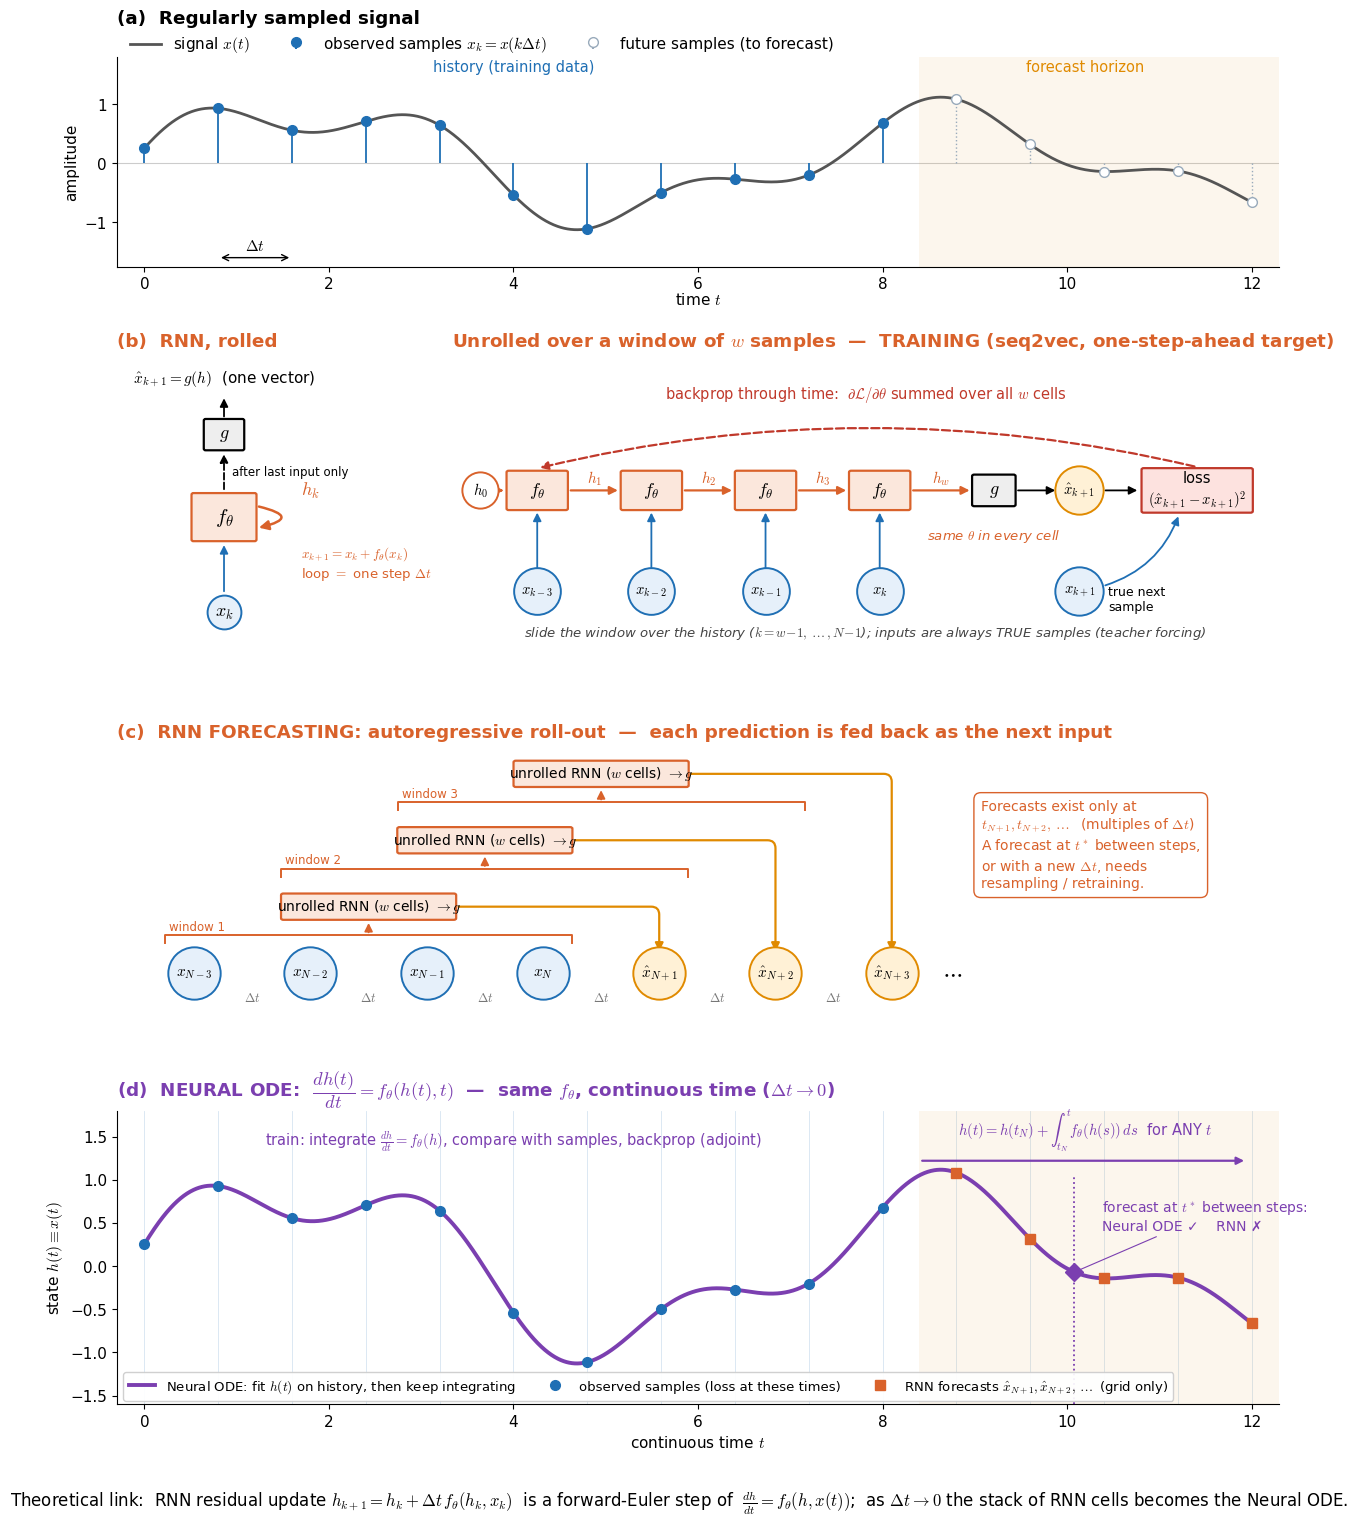

In [ ]:
# @title

import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False,"mathtext.fontset":"cm"})
C_SIG, C_SAMP, C_RNN, C_ODE, C_PRED, C_LOSS = "#555555", "#1f6fb4", "#d9622b", "#7b3fb0", "#e08a00", "#c0392b"

dt, Tobs, Tend, W = 0.8, 8.0, 12.0, 4
x = lambda t: np.exp(-0.03*t)*(np.sin(0.9*t) + 0.45*np.sin(2.3*t + 0.6))
tt = np.linspace(0, Tend, 2000)
tk = np.round(np.arange(0, Tend+1e-9, dt), 6); N = int(round(Tobs/dt))
tobs, tfut = tk[:N+1], tk[N+1:]

def node(ax, x0, y0, txt, fc, ec, r=0.42, fs=10.5, tc="k"):
    ax.plot([x0], [y0], "o", ms=r*58, mfc=fc, mec=ec, mew=1.4, zorder=3)
    ax.text(x0, y0, txt, ha="center", va="center", fontsize=fs, color=tc, zorder=4)
def box(ax, x0, y0, w, h, txt, fc, ec, fs=13):
    ax.add_patch(FancyBboxPatch((x0-w/2, y0-h/2), w, h, boxstyle="round,pad=0.06", fc=fc, ec=ec, lw=1.6, zorder=3))
    ax.text(x0, y0, txt, ha="center", va="center", fontsize=fs, zorder=4)
def arr(ax, a, b, c="k", lw=1.3, ls="-", cs="arc3", ms=12):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", color=c, lw=lw, ls=ls, connectionstyle=cs, mutation_scale=ms, zorder=2))

fig = plt.figure(figsize=(15, 17.5))
gs = fig.add_gridspec(4, 2, height_ratios=[0.75, 1.0, 0.95, 1.05], width_ratios=[1, 2.7], hspace=0.38, wspace=0.05)

# ---------------- (a) signal ----------------
ax0 = fig.add_subplot(gs[0, :])
ax0.axvspan(Tobs+dt/2, Tend+0.3, color=C_PRED, alpha=0.07, lw=0)
ax0.plot(tt, x(tt), color=C_SIG, lw=2, label=r"signal $x(t)$")
ml, sl, _ = ax0.stem(tobs, x(tobs), basefmt=" ", label=r"observed samples $x_k=x(k\Delta t)$")
plt.setp(sl, color=C_SAMP, lw=1.3); plt.setp(ml, color=C_SAMP, ms=7)
ml, sl, _ = ax0.stem(tfut, x(tfut), basefmt=" ", label="future samples (to forecast)")
plt.setp(sl, color="#9ab", lw=1, ls=":"); plt.setp(ml, mfc="white", mec="#9ab", ms=7)
ax0.axhline(0, color="#ccc", lw=0.8, zorder=0)
ax0.annotate("", xy=(tk[2], -1.6), xytext=(tk[1], -1.6), arrowprops=dict(arrowstyle="<->"))
ax0.text((tk[1]+tk[2])/2, -1.53, r"$\Delta t$", ha="center", va="bottom")
ax0.text(Tobs/2, 1.55, "history (training data)", ha="center", color=C_SAMP, fontsize=10.5)
ax0.text((Tobs+Tend)/2+0.2, 1.55, "forecast horizon", ha="center", color=C_PRED, fontsize=10.5)
ax0.set_xlim(-0.3, Tend+0.3); ax0.set_ylim(-1.75, 1.8); ax0.set_xlabel("time $t$", labelpad=0); ax0.set_ylabel("amplitude")
ax0.set_title("(a)  Regularly sampled signal", loc="left", fontweight="bold", pad=24)
ax0.legend(loc="upper left", bbox_to_anchor=(0, 1.17), frameon=False, ncol=3)

# ---------------- (b-left) rolled RNN ----------------
ax1 = fig.add_subplot(gs[1, 0]); ax1.set_axis_off(); ax1.set_xlim(0, 10); ax1.set_ylim(0, 10)
ax1.set_title("(b)  RNN, rolled", loc="left", fontweight="bold", color=C_RNN, pad=14)
node(ax1, 3.5, 1.2, r"$x_k$", "#e6f0fa", C_SAMP, fs=13)
box(ax1, 3.5, 4.6, 2.0, 1.6, r"$f_\theta$", "#fbe7dc", C_RNN, fs=15)
arr(ax1, (3.5, 1.85), (3.5, 3.7), C_SAMP)
arr(ax1, (4.55, 5.0), (4.55, 4.2), C_RNN, lw=1.8, cs="arc3,rad=-2.2", ms=14)
ax1.text(6.0, 5.55, r"$h_k$", color=C_RNN, fontsize=13, va="center")
ax1.text(6.0, 3.6, r"$x_{k+1}=x_k+f_\theta(x_k)$" + "\n" + r"loop $=$ one step $\Delta t$", color=C_RNN, fontsize=9.5, va="top")
arr(ax1, (3.5, 5.5), (3.5, 6.95), "k", ls="--")
ax1.text(3.75, 6.2, "after last input only", fontsize=8.5, va="center")
box(ax1, 3.5, 7.55, 1.2, 1.0, r"$g$", "#eeeeee", "k")
arr(ax1, (3.5, 8.1), (3.5, 8.95))
ax1.text(3.5, 9.2, r"$\hat x_{k+1}=g(h)$  (one vector)", ha="center", va="bottom", fontsize=11)

# ---------------- (b-right) unrolled, training ----------------
ax2 = fig.add_subplot(gs[1, 1]); ax2.set_axis_off(); ax2.set_xlim(-0.6, 22.6); ax2.set_ylim(-0.8, 10)
ax2.set_title("Unrolled over a window of $w$ samples  —  TRAINING (seq2vec, one-step-ahead target)",
              loc="left", fontweight="bold", color=C_RNN, pad=14)
xs = [1.8, 5.0, 8.2, 11.4]; lab = [r"$x_{k-3}$", r"$x_{k-2}$", r"$x_{k-1}$", r"$x_{k}$"]
yh = 5.2
node(ax2, 0.2, yh, r"$h_0$", "white", C_RNN, r=0.45)
prev = 0.65
for i, (xc, l) in enumerate(zip(xs, lab)):
    node(ax2, xc, 1.3, l, "#e6f0fa", C_SAMP, r=0.58)
    arr(ax2, (xc, 1.9), (xc, yh-0.75), C_SAMP)
    box(ax2, xc, yh, 1.6, 1.4, r"$f_\theta$", "#fbe7dc", C_RNN)
    arr(ax2, (prev, yh), (xc-0.86, yh), C_RNN, lw=1.6)
    if i: ax2.text((prev+xc-0.86)/2, yh+0.28, rf"$h_{{{i}}}$", ha="center", fontsize=11, color=C_RNN)
    prev = xc+0.86
ax2.text(14.6, 3.3, r"same $\theta$ in every cell", ha="center", fontsize=9.5, color=C_RNN, style="italic")
arr(ax2, (prev, yh), (14.0, yh), C_RNN, lw=1.6); ax2.text((prev+14)/2, yh+0.28, r"$h_w$", ha="center", fontsize=11, color=C_RNN)
box(ax2, 14.6, yh, 1.1, 1.1, r"$g$", "#eeeeee", "k")
arr(ax2, (15.2, yh), (16.4, yh))
node(ax2, 17.0, yh, r"$\hat x_{k+1}$", "#fff1d6", C_PRED, r=0.6)
node(ax2, 17.0, 1.3, r"$x_{k+1}$", "#e6f0fa", C_SAMP, r=0.6)
ax2.text(17.8, 1.0, "true next\nsample", fontsize=9, ha="left", va="center")
box(ax2, 20.3, yh, 3.0, 1.6, r"loss" + "\n" + r"$(\hat x_{k+1}-x_{k+1})^2$", "#fde2df", C_LOSS, fs=10.5)
arr(ax2, (17.65, yh), (18.7, yh)); arr(ax2, (17.65, 1.5), (19.8, yh-0.9), C_SAMP, cs="arc3,rad=0.25")
# BPTT
arr(ax2, (20.3, yh+0.9), (1.8, yh+0.85), C_LOSS, lw=1.6, ls="--", cs="arc3,rad=0.12")
ax2.text(11.0, 8.75, r"backprop through time:  $\partial\mathcal{L}/\partial\theta$ summed over all $w$ cells",
         ha="center", fontsize=10.5, color=C_LOSS)
ax2.text(11.0, -0.45, r"slide the window over the history ($k = w\!-\!1,\dots,N\!-\!1$); inputs are always TRUE samples (teacher forcing)",
         ha="center", fontsize=9.5, color="#444", style="italic")

# ---------------- (c) unrolled, forecasting ----------------
ax3 = fig.add_subplot(gs[2, :]); ax3.set_axis_off(); ax3.set_xlim(0, 30); ax3.set_ylim(-0.2, 9.6)
ax3.set_title("(c)  RNN FORECASTING: autoregressive roll-out  —  each prediction is fed back as the next input",
              loc="left", fontweight="bold", color=C_RNN)
px = [2.0 + 3.0*i for i in range(7)]
labs = [r"$x_{N-3}$", r"$x_{N-2}$", r"$x_{N-1}$", r"$x_N$", r"$\hat x_{N+1}$", r"$\hat x_{N+2}$", r"$\hat x_{N+3}$"]
for i, (p, l) in enumerate(zip(px, labs)):
    if i < 4: node(ax3, p, 1.2, l, "#e6f0fa", C_SAMP, r=0.65, fs=11)
    else:     node(ax3, p, 1.2, l, "#fff1d6", C_PRED, r=0.65, fs=11)
for i in range(6): ax3.text((px[i]+px[i+1])/2, 0.15, r"$\Delta t$", ha="center", fontsize=9, color="#777")
ax3.text(px[6]+1.3, 1.2, r"$\cdots$", fontsize=16, va="center")
for j in range(3):
    yb = 2.6 + 2.45*j
    a, b = px[j]-0.75, px[j+3]+0.75
    ax3.plot([a, a, b, b], [yb-0.3, yb, yb, yb-0.3], color=C_RNN, lw=1.4)
    ax3.text(a+0.1, yb+0.18, f"window {j+1}", fontsize=8.5, color=C_RNN)
    cx = (a+b)/2
    arr(ax3, (cx, yb), (cx, yb+0.55), C_RNN)
    box(ax3, cx, yb+1.05, 4.4, 0.85, r"unrolled RNN ($w$ cells) $\rightarrow g$", "#fbe7dc", C_RNN, fs=10)
    arr(ax3, (cx+2.25, yb+1.05), (px[j+4], 1.9), C_PRED, lw=1.6, cs="angle,angleA=0,angleB=90,rad=8")
ax3.text(22.3, 7.6, "Forecasts exist only at\n" + r"$t_{N+1}, t_{N+2}, \dots$  (multiples of $\Delta t$)" +
         "\nA forecast at $t^\\ast$ between steps,\nor with a new $\\Delta t$, needs\nresampling / retraining.",
         fontsize=10, color=C_RNN, va="top",
         bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=C_RNN, lw=1))

# ---------------- (d) Neural ODE ----------------
ax4 = fig.add_subplot(gs[3, :])
ax4.axvspan(Tobs+dt/2, Tend+0.3, color=C_PRED, alpha=0.07, lw=0)
for t_ in tk: ax4.axvline(t_, color=C_SAMP, lw=0.6, alpha=0.18, zorder=0)
ax4.plot(tt, x(tt), color=C_ODE, lw=2.8, label=r"Neural ODE: fit $h(t)$ on history, then keep integrating", zorder=3)
ax4.plot(tobs, x(tobs), "o", color=C_SAMP, ms=7, zorder=4, label="observed samples (loss at these times)")
ax4.plot(tfut, x(tfut), "s", color=C_RNN, ms=7.5, zorder=5, label=r"RNN forecasts $\hat x_{N+1},\hat x_{N+2},\dots$ (grid only)")
ax4.annotate("", xy=(Tend-0.05, 1.22), xytext=(Tobs+0.4, 1.22), arrowprops=dict(arrowstyle="-|>", color=C_ODE, lw=1.6))
ax4.text((Tobs+Tend)/2+0.2, 1.3, r"$h(t)=h(t_N)+\int_{t_N}^{t} f_\theta(h(s))\,ds$  for ANY $t$", ha="center", va="bottom", fontsize=10.5, color=C_ODE)
ax4.text(Tobs/2, 1.4, r"train: integrate $\frac{dh}{dt}=f_\theta(h)$, compare with samples, backprop (adjoint)", ha="center", fontsize=10.5, color=C_ODE)
tstar = Tobs + 2.6*dt
ax4.plot([tstar, tstar], [-1.6, 1.05], color=C_ODE, ls=":", lw=1.3)
ax4.plot(tstar, x(tstar), "D", color=C_ODE, ms=9, zorder=6)
ax4.annotate(r"forecast at $t^\ast$ between steps:" + "\nNeural ODE ✓    RNN ✗", xy=(tstar, x(tstar)), xytext=(tstar+0.3, 0.42),
             fontsize=10, color=C_ODE, arrowprops=dict(arrowstyle="-", color=C_ODE, lw=0.8))
ax4.set_xlim(-0.3, Tend+0.3); ax4.set_ylim(-1.6, 1.8)
ax4.set_xlabel("continuous time $t$"); ax4.set_ylabel(r"state $h(t) \equiv x(t)$")
ax4.set_title(r"(d)  NEURAL ODE:  $\dfrac{dh(t)}{dt}=f_\theta(h(t),t)$  —  same $f_\theta$, continuous time ($\Delta t\to 0$)",
              loc="left", fontweight="bold", color=C_ODE, pad=10)
ax4.legend(loc="lower left", fontsize=9.5, frameon=True, framealpha=0.92, ncol=3, bbox_to_anchor=(0, -0.01))

fig.text(0.5, 0.052,
  r"Theoretical link:  RNN residual update $h_{k+1}=h_k+\Delta t\,f_\theta(h_k,x_k)$  is a forward-Euler step of  $\frac{dh}{dt}=f_\theta(h,x(t))$;  "
  r"as $\Delta t\to 0$ the stack of RNN cells becomes the Neural ODE.", ha="center", fontsize=12)

fig.savefig("rnn_vs_neuralode_forecasting.png", dpi=200, bbox_inches="tight")
fig.savefig("rnn_vs_neuralode_forecasting.pdf", bbox_inches="tight")


## **RNN learn discrete points on signal, while NODE learn the vector field to generate continuous signals**

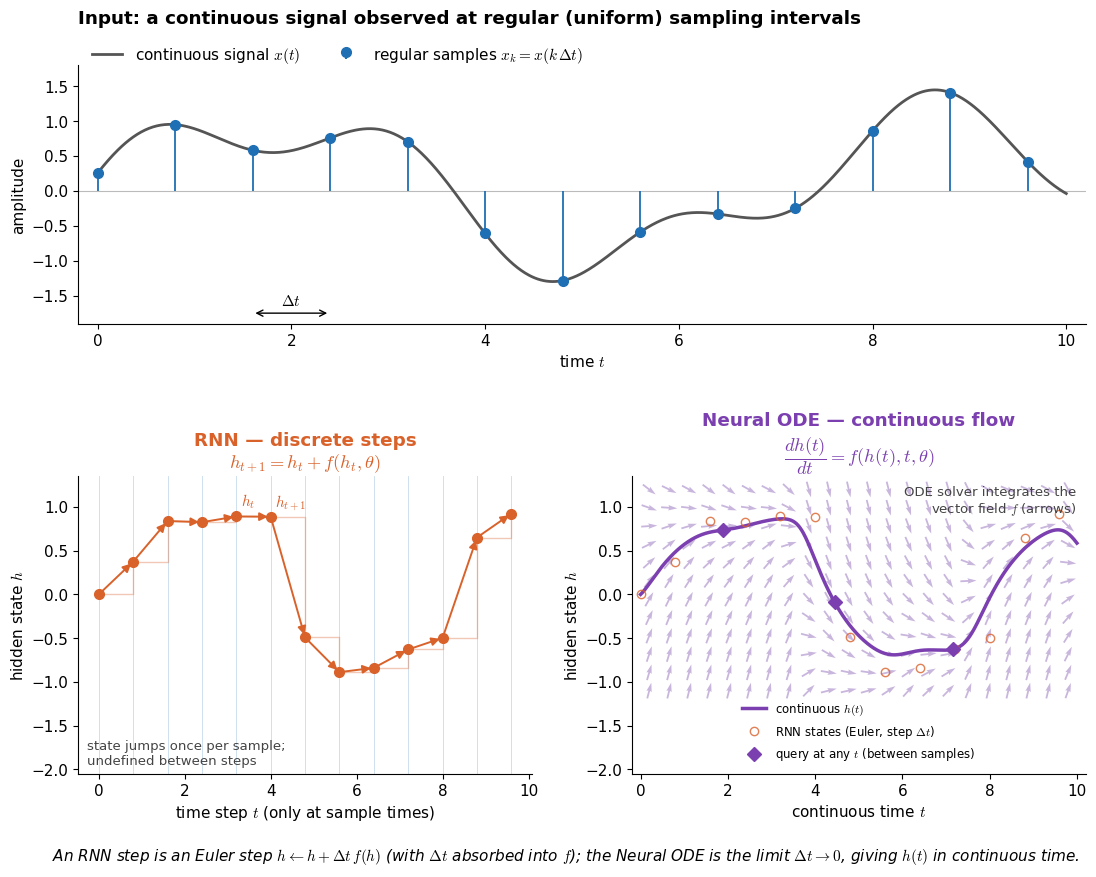

In [ ]:
# @title

import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle
from scipy.integrate import solve_ivp
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False,"mathtext.fontset":"cm"})
C_SIG, C_SAMP, C_RNN, C_RES, C_ODE = "#555555", "#1f6fb4", "#d9622b", "#2a9d5c", "#7b3fb0"

# signal + regular samples
T = 10; dt = 0.8
t = np.linspace(0, T, 1000)
x = lambda tt: np.sin(0.9*tt) + 0.45*np.sin(2.3*tt + 0.6)
ts = np.arange(0, T+1e-9, dt); xs = x(ts)

# shared dynamics f(h, x) = -h + tanh(2x)
f = lambda h, xx: -h + np.tanh(2*xx)

fig = plt.figure(figsize=(13, 9.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.55, wspace=0.22)

# ---- top: signal ----
ax0 = fig.add_subplot(gs[0, :])
ax0.plot(t, x(t), color=C_SIG, lw=2, label=r"continuous signal $x(t)$")
ml, sl, bl = ax0.stem(ts, xs, basefmt=" ", label=r"regular samples $x_k = x(k\,\Delta t)$")
plt.setp(sl, color=C_SAMP, lw=1.3); plt.setp(ml, color=C_SAMP, ms=7)
ax0.axhline(0, color="#bbbbbb", lw=0.8, zorder=0)
ax0.annotate("", xy=(ts[3], -1.75), xytext=(ts[2], -1.75), arrowprops=dict(arrowstyle="<->", color="k"))
ax0.text((ts[2]+ts[3])/2, -1.68, r"$\Delta t$", ha="center", va="bottom")
ax0.set_xlim(-0.2, T+0.2); ax0.set_ylim(-1.9, 1.8)
ax0.set_xlabel("time $t$"); ax0.set_ylabel("amplitude")
ax0.set_title("Input: a continuous signal observed at regular (uniform) sampling intervals", loc="left", fontweight="bold", pad=30)
ax0.legend(loc="upper left", bbox_to_anchor=(0, 1.13), frameon=False, ncol=2)

# ---- RNN: discrete steps ----
ax1 = fig.add_subplot(gs[1, 0])
h = [0.0]
for k in range(len(ts)-1): h.append(h[-1] + dt*f(h[-1], xs[k]))
h = np.array(h)
ax1.step(ts, h, where="post", color=C_RNN, lw=1, alpha=0.35)
for k in range(len(ts)-1):
    ax1.annotate("", xy=(ts[k+1], h[k+1]), xytext=(ts[k], h[k]),
                 arrowprops=dict(arrowstyle="-|>", color=C_RNN, lw=1.4, mutation_scale=12))
ax1.plot(ts, h, "o", color=C_RNN, ms=7, zorder=3)
for tk in ts: ax1.axvline(tk, color=C_SAMP, lw=0.6, alpha=0.25, zorder=0)
ax1.text(ts[4]+0.1, h[4]+0.12, r"$h_t$", color=C_RNN); ax1.text(ts[5]+0.1, h[5]+0.12, r"$h_{t+1}$", color=C_RNN)
ax1.set_xlabel("time step $t$ (only at sample times)"); ax1.set_ylabel("hidden state $h$")
ax1.set_title("RNN — discrete steps\n" + r"$h_{t+1} = h_t + f(h_t, \theta)$", color=C_RNN, fontweight="bold")
ax1.set_ylim(-2.05, 1.35)
ax1.text(0.02, 0.03, "state jumps once per sample;\nundefined between steps", transform=ax1.transAxes, fontsize=9.5, color="#444")

# ---- Neural ODE: continuous flow ----
ax3 = fig.add_subplot(gs[1, 1])
sol = solve_ivp(lambda tt, hh: f(hh, x(tt)), (0, T), [0.0], dense_output=True, rtol=1e-8)
tq, hq = np.meshgrid(np.linspace(0.2, T-0.2, 22), np.linspace(-1.1, 1.2, 12))
dh = f(hq, x(tq)); n = np.sqrt(1+dh**2)
ax3.quiver(tq, hq, 1/n, dh/n, color="#c9b6dd", angles="xy", pivot="mid", scale=28, width=0.004, zorder=0)
ax3.plot(t, sol.sol(t)[0], color=C_ODE, lw=2.5, label=r"continuous $h(t)$")
ax3.plot(ts, h, "o", mfc="none", mec=C_RNN, ms=6, alpha=0.8, label="RNN states (Euler, step $\\Delta t$)")
tany = np.array([1.9, 4.45, 7.15])
ax3.plot(tany, sol.sol(tany)[0], "D", color=C_ODE, ms=7, label="query at any $t$ (between samples)")
ax3.set_xlabel("continuous time $t$"); ax3.set_ylabel("hidden state $h$")
ax3.set_title("Neural ODE — continuous flow\n" + r"$\dfrac{dh(t)}{dt} = f(h(t), t, \theta)$", color=C_ODE, fontweight="bold")
ax3.set_ylim(-2.05, 1.35); ax3.set_xlim(-0.2, T+0.2)
ax3.legend(loc="lower center", fontsize=8.5, frameon=False, ncol=1)
ax3.text(0.98, 0.97, "ODE solver integrates the\nvector field $f$ (arrows)", transform=ax3.transAxes, ha="right", va="top", fontsize=9.5, color="#444")

fig.text(0.5, 0.015, r"An RNN step is an Euler step $h \leftarrow h + \Delta t\, f(h)$ (with $\Delta t$ absorbed into $f$); "
         r"the Neural ODE is the limit $\Delta t \to 0$, giving $h(t)$ in continuous time.", ha="center", fontsize=11, style="italic")
fig.savefig("signal_rnn_neuralode.png", dpi=200, bbox_inches="tight")
fig.savefig("signal_rnn_neuralode.pdf", bbox_inches="tight")


## **Advantages of NDEs over RNNs for Time-Series**:
While both handle sequential data, Neural ODEs solve several fundamental flaws inherent to traditional RNNs when dealing with real-world time-series.
1. **Irregularly Sampled** Data:
- Standard RNNs: assume data arrives at fixed, equal intervals (e.g., every hour). If a patient in a hospital has vitals taken at 2:00 AM, 2:15 AM, and then not until 7:00 AM, an RNN struggles to naturally process the blank gap without arbitrary padding or masking.
- NDEs: Because the underlying model is a continuous differential equation, we can evaluate the hidden state at any arbitrary timestamp $t$.
2. **Continuous-Time Latent Dynamics**
- RNNs: The hidden states in RNN only update when a new data point is observed. Between observations, the model is completely static.  Transformers leverage self-attention mechanisms, but rely on fixed positional encodings and do not inherently capture continuous-time dynamics.
- NDEs: Learning differntial equations using neural net directly within a solver means it is learning the underlying continuous-time dynamics of the system.
3. Memory Efficiency
- RNNs: Training an RNN over long time series requires storing all intermediate hidden states in memory for Backpropagation Through Time (BPTT), leading to high VRAM consumption.
- NDEs: By using the **adjoint sensitivity method**, Neural ODEs can compute gradients across the sequence without storing intermediate states, operating with constant $\mathcal{O}(1)$ memory cost relative to the sequence length.

## **Hybrid RNN ODE Models**:
GRU-ODE and Latent ODE: As they are so closely related, recent models use them in combination. In a Latent ODE or GRU-ODE-Bayes architecture: An RNN or GRU processes incoming discrete observations. Between observations, a Neural ODE takes over to continuously transition the hidden state forward through time until the next data point arrives.

## **Advantages of NDEs over RNNs: Irregular Sampled Data**

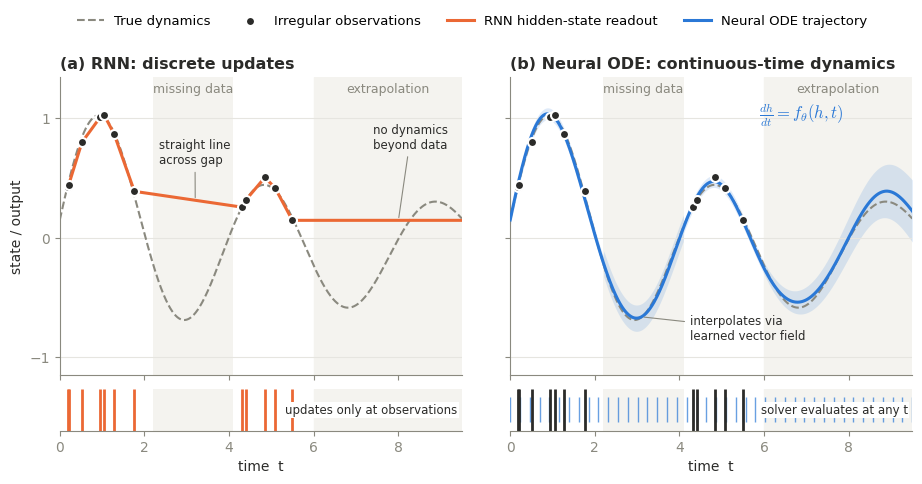

In [ ]:

# @title

"""Motivating figure: Neural ODE vs RNN on irregularly sampled time series.

Schematic (not a trained-model result): the RNN hidden state only changes at
observation times (zero-order hold between them, flat extrapolation), while the
Neural ODE hidden state evolves continuously, so it can be read out at any t,
interpolate across gaps, and extrapolate the dynamics.
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

rng = np.random.default_rng(3)

# Ground-truth dynamics: damped oscillator
def truth(t):
    return np.exp(-0.12 * t) * np.sin(1.6 * t) + 0.15 * np.cos(0.5 * t)

T_OBS, T_END = 6.0, 9.5
t = np.linspace(0, T_END, 800)

# Irregular observations, with a deliberate long gap (sensor dropout)
t_obs = np.sort(np.concatenate([rng.uniform(0.0, 2.2, 7), rng.uniform(4.1, T_OBS, 5)]))
y_obs = truth(t_obs) + rng.normal(0, 0.04, t_obs.size)
gap = (2.2, 4.1)

# RNN: readout only defined at observations; connect them with straight lines,
# held constant after the last observation (no dynamics beyond data)
rnn = np.where(t >= t_obs[0], np.interp(t, t_obs, y_obs), np.nan)

# Neural ODE: smooth continuous trajectory (small model error, growing in extrapolation)
nde = truth(t) + 0.03 * np.sin(3 * t) + np.where(t > T_OBS, 0.02 * (t - T_OBS), 0)
band = 0.05 + np.where(t > T_OBS, 0.06 * (t - T_OBS), 0) + np.where((t > gap[0]) & (t < gap[1]), 0.06, 0)

# Colors (validated categorical slots 1 & 2), neutral ink for ground truth
C_NDE, C_RNN, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#2b2b29", "#8a897f", "#e6e5e0"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
})

fig, axes = plt.subplots(
    2, 2, figsize=(11, 4.6), sharex=True,
    gridspec_kw={"height_ratios": [5, 0.7], "hspace": 0.08, "wspace": 0.12},
)

panels = [
    ("(a) RNN: discrete updates", rnn, C_RNN, "RNN hidden-state readout"),
    ("(b) Neural ODE: continuous-time dynamics", nde, C_NDE, "Neural ODE trajectory"),
]

for col, (title, pred, color, lab) in enumerate(panels):
    ax, strip = axes[0, col], axes[1, col]
    for a in (ax, strip):
        a.axvspan(T_OBS, T_END, color="#f4f3ef", zorder=0)
        a.axvspan(*gap, color="#f4f3ef", zorder=0, lw=0)

    ax.plot(t, truth(t), color=MUTED, lw=1.5, ls="--", label="True dynamics", zorder=2)
    if col == 1:
        ax.fill_between(t, pred - band, pred + band, color=color, alpha=0.15, lw=0, zorder=1)
    ax.plot(t, pred, color=color, lw=2.2, label=lab, zorder=3)
    ax.scatter(t_obs, y_obs, s=42, color=INK, edgecolor="white", lw=1.5, zorder=4,
               label="Irregular observations")

    ax.set_title(title, loc="left", fontsize=11.5, color=INK, fontweight="bold")
    ax.set_ylim(-1.15, 1.35)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_yticks([-1, 0, 1])
    ax.text((gap[0] + gap[1]) / 2, 1.22, "missing data", ha="center", fontsize=9, color=MUTED)
    ax.text((T_OBS + T_END) / 2, 1.22, "extrapolation", ha="center", fontsize=9, color=MUTED)

    # Strip: when does the model compute?
    if col == 0:
        strip.vlines(t_obs, 0, 1, color=C_RNN, lw=2)
        strip.text(T_END - 0.1, 0.5, "updates only at observations", ha="right",
                   va="center", fontsize=8.5, color=INK, bbox=dict(fc="white", ec="none", pad=1))
    else:
        t_eval = np.sort(np.concatenate([np.linspace(0, T_END, 42), t_obs]))
        strip.vlines(t_eval, 0.2, 0.8, color=C_NDE, lw=1, alpha=0.7)
        strip.vlines(t_obs, 0, 1, color=INK, lw=2)
        strip.text(T_END - 0.1, 0.5, "solver evaluates at any t", ha="right", va="center",
                   fontsize=8.5, color=INK,
                   bbox=dict(fc="white", ec="none", pad=1))
    strip.set_ylim(0, 1)
    strip.set_yticks([])
    strip.spines["left"].set_visible(False)
    strip.set_xlim(0, T_END)
    strip.set_xlabel("time  t")

axes[0, 0].set_ylabel("state / output")
axes[0, 1].tick_params(labelleft=False)

# Callouts on the failure modes vs strengths
axes[0, 0].annotate("straight line\nacross gap", xy=(3.2, rnn[np.searchsorted(t, 3.2)]),
                    xytext=(2.35, 0.62), fontsize=8.5, color=INK,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
axes[0, 0].annotate("no dynamics\nbeyond data", xy=(8.0, rnn[-1]), xytext=(7.4, 0.75),
                    fontsize=8.5, color=INK,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
axes[0, 1].annotate("interpolates via\nlearned vector field", xy=(3.1, nde[np.searchsorted(t, 3.1)]),
                    xytext=(4.25, -0.85), fontsize=8.5, color=INK,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
axes[0, 1].annotate(r"$\frac{dh}{dt}=f_\theta(h,t)$", xy=(0.5, 0.5), xycoords="axes fraction",
                    xytext=(0.62, 0.86), textcoords="axes fraction", fontsize=12, color=C_NDE)

h0, l0 = axes[0, 0].get_legend_handles_labels()
h1, l1 = axes[0, 1].get_legend_handles_labels()
fig.legend([h0[0], h0[2], h0[1], h1[1]], [l0[0], l0[2], l0[1], l1[1]],
           loc="upper center", ncol=4, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 1.04))